# AI Model Experiment & Evaluation
Sentiment analysis ulasan pelanggan: model klasik (Scikit-learn) vs LLM API (Gemini)

Di notebook ini saya membandingkan dua cara untuk menebak sentimen ulasan:
1. Model klasik: TF-IDF + Logistic Regression
2. LLM: Gemini, cukup pakai prompt tanpa training

Catatan: jawaban Gemini sudah saya simpan di `documentation/llm_predictions.csv`, jadi notebook bisa langsung di-Run All tanpa API key.
Kalau mau memanggil Gemini lagi, hapus dulu file csv tersebut.

## 1. Problem Statement

Tim produk e-commerce mau membuat fitur yang otomatis menandai ulasan pelanggan sebagai positif atau negatif di halaman produk.
Di sini saya mencoba dua pendekatan (model klasik yang dilatih sendiri dan LLM tanpa training), lalu memberi saran mana yang sebaiknya dipakai
dengan melihat hasilnya, effort, kecepatan, dan biaya.

Label yang ditebak ada di kolom `sentiment`:
- `positif`: pembeli puas (barang sesuai, kualitas bagus, pengiriman cepat, pelayanan oke)
- `negatif`: pembeli kecewa atau komplain (barang rusak, palsu, tidak sesuai, pengiriman lama, pelayanan buruk)

Batasan dan asumsi yang saya pakai:
- Input-nya hanya `review_text`. `product_name` tidak dipakai karena sentimennya ada di isi ulasan.
- Hanya ada 2 kelas, jadi ulasan yang netral atau campuran tetap harus masuk salah satunya.
- Label di dataset saya anggap sudah benar, dan file aslinya tidak diubah.
- Kedua pendekatan dites dengan test set yang sama.
- Gemini dipakai apa adanya (tanpa fine-tuning) dengan kuota API gratis.

## 2. Import Library & Load Dataset

In [1]:
import os
import time

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from google import genai
from google.genai import types
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split

LABELS = ['negatif', 'positif']
DOC_DIR = '../documentation'

df = pd.read_csv('../data/customer_reviews_sentiment.csv')
print('Jumlah baris:', len(df))
df.head()

Jumlah baris: 200


,review_id,product_name,review_text,sentiment
0,1,Kemeja Flanel,Pelayanan lambat dan tidak responsif saat diko...,negatif
1,2,Case HP,"Puas banget belanja disini, proses cepat dan b...",positif
2,3,Rice Cooker,"Terima kasih seller, barangnya awet dan sesuai...",positif
3,4,Case HP,Warna produk berbeda jauh dari foto di listing.,negatif
4,5,Headset Bluetooth,"Terima kasih seller, barangnya awet dan sesuai...",positif


In [2]:
print('Missing value per kolom:')
print(df.isna().sum())
print()
print('Distribusi sentiment:')
print(df['sentiment'].value_counts())
print()
print('Jumlah produk :', df['product_name'].nunique())
print('Jumlah ulasan :', len(df))
print('Jumlah kalimat ulasan yang unik:', df['review_text'].nunique())

Missing value per kolom:
review_id       0
product_name    0
review_text     0
sentiment       0
dtype: int64

Distribusi sentiment:
sentiment
positif    110
negatif     90
Name: count, dtype: int64

Jumlah produk : 15
Jumlah ulasan : 200
Jumlah kalimat ulasan yang unik: 40


In [3]:
# Kalimat yang paling sering muncul berulang
df['review_text'].value_counts().head(10)

review_text
Bahan nyaman dipakai, ukuran pas, tidak mengecewakan.                      12
Produknya rapi dan bersih, tidak ada cacat sama sekali.                     9
Pengiriman lambat sekali, sudah dua minggu belum sampai.                    8
Kualitas produk jelek, baru dipakai sekali sudah rusak.                     8
Pelayanan ramah dan responsif, barang sampai lebih cepat dari estimasi.     8
Packing rapi, produk sesuai deskripsi. Recommended seller!                  7
Produk original dan berfungsi dengan baik, terima kasih!                    7
Sangat puas dengan pembelian ini, akan beli lagi di lain waktu.             7
Respon penjual lambat dan terkesan tidak peduli komplain.                   7
Fast respon, pengiriman cepat, barang aman sampai tujuan.                   7
Name: count, dtype: int64

**Catatan:** tidak ada missing value dan labelnya cukup seimbang (110 positif, 90 negatif).
Yang menarik, 200 ulasan ini ternyata cuma berisi 40 kalimat yang berbeda. Kalimatnya diulang-ulang (ada yang sampai 12 kali), yang beda hanya nama produknya.
Ini bisa jadi masalah waktu split, karena kalimat yang sama bisa masuk ke train dan test sekaligus. Saya cek di bagian 3.

## 3. Menyiapkan Train/Test Split

Test set yang sama dipakai untuk kedua pendekatan supaya perbandingannya adil.

**Skenario A:** split 80/20 per baris, sama seperti di starter notebook (`stratify` dan `random_state=42`).

In [4]:
X = df['review_text']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Train size:', len(X_train))
print('Test size:', len(X_test))

Train size: 160
Test size: 40


In [5]:
# Cek: berapa kalimat di test set yang juga ada di train set?
sudah_ada_di_train = X_test.isin(X_train)
print(f'{sudah_ada_di_train.sum()} dari {len(X_test)} ulasan test kalimatnya sama persis dengan ulasan di train set')

39 dari 40 ulasan test kalimatnya sama persis dengan ulasan di train set


**Catatan:** ternyata 39 dari 40 ulasan di test set kalimatnya sudah ada di train set.
Jadi kalau model klasik dapat nilai bagus di sini, itu lebih karena dia sudah "hafal" kalimatnya, bukan karena paham.
Untuk Gemini tidak masalah, karena Gemini tidak dilatih dengan train set ini. Karena itu saya tambahkan satu skenario lagi di bawah.

**Skenario B:** split dilakukan per kalimat unik, jadi kalimat yang masuk test set benar-benar tidak ada di train set.
Dengan begini bisa kelihatan bagaimana model menghadapi kalimat yang belum pernah dia lihat.

In [6]:
kalimat_unik = df.drop_duplicates('review_text')
kalimat_train, kalimat_test = train_test_split(
    kalimat_unik['review_text'], test_size=0.2, random_state=42, stratify=kalimat_unik['sentiment']
)

test_b = df[df['review_text'].isin(kalimat_test)]
train_b = df[~df['review_text'].isin(kalimat_test)]
X_train_b, y_train_b = train_b['review_text'], train_b['sentiment']
X_test_b, y_test_b = test_b['review_text'], test_b['sentiment']

print('Train B:', len(X_train_b), 'baris |', X_train_b.nunique(), 'kalimat unik')
print('Test B :', len(X_test_b), 'baris |', X_test_b.nunique(), 'kalimat unik')
print('Kalimat test B yang ada di train B:', X_test_b.isin(X_train_b).sum())

Train B: 158 baris | 32 kalimat unik
Test B : 42 baris | 8 kalimat unik
Kalimat test B yang ada di train B: 0


## 4. Pendekatan 1: Model Klasik (Scikit-learn)

### 4.1 Preprocessing & Feature Extraction

Teks diubah jadi angka dengan `TfidfVectorizer`. Secara default dia sudah mengubah teks ke huruf kecil dan memecah kalimat jadi kata,
jadi saya tidak menambahkan preprocessing lain.

Stopword tidak saya hapus. Daftar stopword bawaan sklearn hanya untuk bahasa Inggris, dan kata seperti "tidak" justru penting untuk menentukan sentimen.

In [7]:
vectorizer = TfidfVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print('Shape TF-IDF train:', X_train_vec.shape)
print('Contoh kosakata:', vectorizer.get_feature_names_out()[:15])

Shape TF-IDF train: (160, 145)
Contoh kosakata: ['ada' 'akan' 'aman' 'asal' 'asalan' 'awet' 'bagian' 'bagus' 'bahan'
 'baik' 'banget' 'barang' 'barangnya' 'baru' 'bayar']


### 4.2 Training Model

Modelnya `LogisticRegression`, sama seperti di starter notebook.

In [8]:
mulai = time.time()
clf = LogisticRegression()
clf.fit(X_train_vec, y_train)
waktu_training = time.time() - mulai

print(f'Waktu training: {waktu_training:.4f} detik')

Waktu training: 0.0089 detik


In [9]:
# Cek overfitting: bandingkan accuracy di train dan test
print('Train accuracy:', accuracy_score(y_train, clf.predict(X_train_vec)))
print('Test accuracy :', accuracy_score(y_test, clf.predict(X_test_vec)))

Train accuracy: 1.0
Test accuracy : 1.0


In [10]:
# Kata dengan bobot paling besar (negatif = mengarah ke 'negatif', positif = mengarah ke 'positif')
bobot_kata = pd.DataFrame({
    'kata': vectorizer.get_feature_names_out(),
    'bobot': clf.coef_[0],
}).sort_values('bobot')

print('Kata paling negatif:')
print(bobot_kata.head(8).to_string(index=False))
print()
print('Kata paling positif:')
print(bobot_kata.tail(8).to_string(index=False))

Kata paling negatif:
   kata     bobot
 lambat -1.244048
   jauh -1.089960
  sudah -0.952110
  rusak -0.887344
   yang -0.866353
  tidak -0.862761
 sekali -0.827183
seperti -0.766643

Kata paling positif:
       kata    bobot
recommended 0.822086
       puas 0.866747
      lebih 0.891489
        ada 0.948661
        pas 0.964126
     nyaman 0.964126
       rapi 1.070154
      cepat 1.616003


### 4.3 Prediksi pada Test Set

In [11]:
mulai = time.time()
y_pred_classic = clf.predict(X_test_vec)
waktu_prediksi_classic = (time.time() - mulai) / len(X_test)

print(f'Rata-rata waktu prediksi per ulasan: {waktu_prediksi_classic * 1000:.3f} ms')

Rata-rata waktu prediksi per ulasan: 0.000 ms


In [12]:
# Skenario B: latih ulang model dengan train B, lalu prediksi test B
vectorizer_b = TfidfVectorizer()
clf_b = LogisticRegression()
clf_b.fit(vectorizer_b.fit_transform(X_train_b), y_train_b)
y_pred_classic_b = clf_b.predict(vectorizer_b.transform(X_test_b))

print('Train accuracy B:', accuracy_score(y_train_b, clf_b.predict(vectorizer_b.transform(X_train_b))))
print('Test accuracy B :', accuracy_score(y_test_b, y_pred_classic_b))

Train accuracy B: 1.0
Test accuracy B : 0.6904761904761905


## 5. Pendekatan 2: LLM API (Gemini)

### 5.1 Setup API

API key diambil dari environment variable `GEMINI_API_KEY` (atau file `.env`), tidak ditulis langsung di notebook.
Kalau API key tidak ada, notebook tetap bisa jalan karena memakai jawaban Gemini yang sudah tersimpan.

In [13]:
load_dotenv('../.env')
api_key = os.environ.get('GEMINI_API_KEY')
# Kalau tidak ada API key, client tidak dibuat dan notebook memakai jawaban Gemini yang sudah tersimpan di folder documentation
client = genai.Client(api_key=api_key) if api_key else None

MODEL_GEMINI = 'gemini-3.5-flash-lite'
print('Model:', MODEL_GEMINI)

Model: gemini-3.5-flash-lite


### 5.2 Merancang Prompt

Saya pakai **zero-shot**, jadi Gemini langsung diminta menebak tanpa diberi contoh. Alasannya:
- Pendekatan 2 memang tujuannya tanpa training dan tanpa data berlabel.
- Dataset ini banyak kalimat yang berulang. Kalau contoh few-shot diambil dari train set, bisa jadi contohnya sama persis dengan soal di test set, jadi kurang adil.

Prompt dari starter saya tambah sedikit:
- konteks bahwa ini ulasan e-commerce Indonesia,
- definisi positif dan negatif, supaya komplain soal pengiriman dan pelayanan juga dihitung negatif (sesuai label di dataset),
- pengingat soal kata negasi (contohnya saya ambil dari luar dataset),
- minta jawab satu kata saja supaya gampang diolah.

Parameter yang dipakai:
- `model = gemini-3.5-flash-lite`: versi yang ringan dan murah, cukup untuk kalimat pendek. Awalnya saya coba `gemini-2.5-flash`
  tapi error 404 (sudah tidak tersedia), lalu `gemini-3.8-flash` sering error 503 karena servernya sedang penuh.
- `temperature = 0.0`: untuk klasifikasi saya mau jawabannya konsisten, jadi ulasan yang sama selalu dapat jawaban yang sama.
  Di starter nilainya 0.2, saya turunkan karena di sini tidak butuh variasi jawaban.

In [14]:
def buat_prompt(review_text):
    return f'''Kamu adalah sistem klasifikasi sentimen untuk ulasan produk di e-commerce Indonesia.
Klasifikasikan sentimen ulasan berikut sebagai "positif" atau "negatif".

Definisi:
- positif: pelanggan puas, misalnya produk sesuai deskripsi atau berkualitas, pengiriman cepat, pelayanan baik.
- negatif: pelanggan kecewa atau mengeluh, misalnya produk rusak, palsu, atau tidak sesuai, pengiriman lambat, pelayanan buruk.

Perhatikan kata negasi. Contoh: "tidak menyesal beli" berarti positif.
Jawab hanya dengan satu kata: positif atau negatif.

Ulasan: "{review_text}"
Sentimen:'''


def klasifikasi_llm(review_text, max_percobaan=5):
    for percobaan in range(1, max_percobaan + 1):
        try:
            mulai = time.time()
            response = client.models.generate_content(
                model=MODEL_GEMINI,
                contents=buat_prompt(review_text),
                config=types.GenerateContentConfig(temperature=0.0),
            )
            latency = time.time() - mulai
            return response.text, latency, response.usage_metadata
        except Exception as e:
            # Contoh error: 429 (kuota per menit habis) atau 503 (server sedang sibuk)
            print(f'  percobaan {percobaan} gagal: {str(e)[:70]}... tunggu 10 detik')
            time.sleep(10)
    raise RuntimeError('Gemini API gagal dipanggil: ' + review_text)


print(buat_prompt('Contoh ulasan'))

Kamu adalah sistem klasifikasi sentimen untuk ulasan produk di e-commerce Indonesia.
Klasifikasikan sentimen ulasan berikut sebagai "positif" atau "negatif".

Definisi:
- positif: pelanggan puas, misalnya produk sesuai deskripsi atau berkualitas, pengiriman cepat, pelayanan baik.
- negatif: pelanggan kecewa atau mengeluh, misalnya produk rusak, palsu, atau tidak sesuai, pengiriman lambat, pelayanan buruk.

Perhatikan kata negasi. Contoh: "tidak menyesal beli" berarti positif.
Jawab hanya dengan satu kata: positif atau negatif.

Ulasan: "Contoh ulasan"
Sentimen:


### 5.3 Menjalankan Prediksi pada Test Set

Ulasan dari test set A dan B dikirim ke Gemini satu per satu. Selain jawabannya, saya catat juga waktu responsnya dan jumlah token (untuk menghitung biaya).
Semuanya disimpan ke CSV.

Sebelum dibandingkan dengan label asli, jawaban Gemini dinormalisasi dulu: huruf dikecilkan, spasi dibuang, lalu dipetakan ke `positif` atau `negatif`.

In [15]:
def normalisasi_label(jawaban):
    jawaban = str(jawaban).strip().lower()
    if 'negatif' in jawaban:
        return 'negatif'
    if 'positif' in jawaban:
        return 'positif'
    return 'tidak_valid'


def jalankan_llm(data, nama_file):
    """data: DataFrame dengan kolom review_id dan review_text. Hasil disimpan ke documentation/<nama_file>."""
    path = f'{DOC_DIR}/{nama_file}'
    if os.path.exists(path):
        print('Memakai hasil Gemini yang sudah tersimpan:', path)
        return pd.read_csv(path)
    if client is None:
        raise RuntimeError(f'{path} belum ada, isi GEMINI_API_KEY dulu untuk memanggil Gemini')

    hasil = []
    for i, row in enumerate(data.itertuples(), 1):
        jawaban, latency, usage = klasifikasi_llm(row.review_text)
        hasil.append({
            'review_id': row.review_id,
            'review_text': row.review_text,
            'jawaban_llm': jawaban,
            'latency_detik': latency,
            'input_tokens': usage.prompt_token_count,
            'output_tokens': (usage.candidates_token_count or 0) + (usage.thoughts_token_count or 0),
        })
        print(f'[{i}/{len(data)}] {jawaban!r:<12} {latency:.2f} detik | {row.review_text[:55]}')
        time.sleep(1)  # jeda agar tidak terkena batas request per menit

    hasil = pd.DataFrame(hasil)
    hasil.to_csv(path, index=False)
    return hasil

In [16]:
# Ulasan yang perlu diprediksi: gabungan test set A dan test set B
data_llm = df.loc[X_test.index.union(X_test_b.index), ['review_id', 'review_text']]

llm_df = jalankan_llm(data_llm, 'llm_predictions.csv')
llm_df['pred_llm'] = llm_df['jawaban_llm'].apply(normalisasi_label)
pred_per_id = dict(zip(llm_df['review_id'], llm_df['pred_llm']))

y_pred_llm = df.loc[X_test.index, 'review_id'].map(pred_per_id).values
y_pred_llm_b = df.loc[X_test_b.index, 'review_id'].map(pred_per_id).values

print('Jumlah ulasan yang diprediksi Gemini:', len(llm_df))
print('Jawaban tidak valid:', (llm_df['pred_llm'] == 'tidak_valid').sum())
print('Contoh jawaban mentah:', llm_df['jawaban_llm'].unique()[:5])

Memakai hasil Gemini yang sudah tersimpan: ../documentation/llm_predictions.csv
Jumlah ulasan yang diprediksi Gemini: 73
Jawaban tidak valid: 0
Contoh jawaban mentah: <StringArray>
['positif', 'negatif']
Length: 2, dtype: str


## 6. Evaluasi dan Perbandingan

Metrik yang dipakai:
- **Accuracy**: berapa persen tebakan yang benar.
- **Precision**: dari yang ditebak kelas X, berapa yang memang kelas X.
- **Recall**: dari yang aslinya kelas X, berapa yang berhasil ditemukan.
- **F1-Score**: gabungan precision dan recall.

Untuk angka ringkasan saya pakai rata-rata macro (positif dan negatif bobotnya sama).
Saya juga melihat recall kelas negatif secara khusus, karena menurut saya yang paling berbahaya untuk tim produk adalah komplain pelanggan yang tidak terdeteksi.

In [17]:
def hitung_metrik(nama, y_true, y_pred):
    return {
        'Pendekatan': nama,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision (macro)': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'Recall (macro)': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'F1-Score (macro)': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'Recall negatif': recall_score(y_true, y_pred, pos_label='negatif', zero_division=0),
    }


def tampilkan_evaluasi(judul, y_true, y_pred):
    print(f'=== {judul} ===')
    print('Accuracy:', round(accuracy_score(y_true, y_pred), 4))
    print(classification_report(y_true, y_pred, digits=4, zero_division=0))
    print('Confusion Matrix (baris = aktual, kolom = prediksi):')
    print(pd.DataFrame(confusion_matrix(y_true, y_pred, labels=LABELS), index=LABELS, columns=LABELS))

### 6.1 Evaluasi Model Klasik

In [18]:
tampilkan_evaluasi('Model Klasik (Scikit-learn) - Skenario A', y_test, y_pred_classic)

=== Model Klasik (Scikit-learn) - Skenario A ===
Accuracy: 1.0
              precision    recall  f1-score   support

     negatif     1.0000    1.0000    1.0000        18
     positif     1.0000    1.0000    1.0000        22

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40

Confusion Matrix (baris = aktual, kolom = prediksi):
         negatif  positif
negatif       18        0
positif        0       22


**Interpretasi:** semua metrik 1,00. Accuracy 1 berarti ke-40 ulasan ditebak benar.
Precision dan recall 1 berarti tidak ada ulasan positif yang dikira negatif dan tidak ada komplain yang terlewat, jadi F1-nya juga 1.
Train dan test accuracy juga sama-sama 1,00.

Tapi menurut saya hasil ini terlalu bagus untuk dipercaya, karena hampir semua kalimat test sudah ada di train (lihat bagian 3).
Model tinggal mencocokkan kalimat yang sudah dia hafal.

### 6.2 Evaluasi LLM API

In [19]:
tampilkan_evaluasi('LLM API (Gemini) - Skenario A', y_test, y_pred_llm)

=== LLM API (Gemini) - Skenario A ===
Accuracy: 1.0
              precision    recall  f1-score   support

     negatif     1.0000    1.0000    1.0000        18
     positif     1.0000    1.0000    1.0000        22

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40

Confusion Matrix (baris = aktual, kolom = prediksi):
         negatif  positif
negatif       18        0
positif        0       22


**Interpretasi:** Gemini juga dapat 1,00 di semua metrik. Bedanya, Gemini sama sekali tidak melihat train set, jadi nilainya bukan dari hafalan.
Semua jawabannya juga langsung `positif` atau `negatif`, tidak ada jawaban aneh yang perlu dibuang.

### 6.3 Evaluasi Skenario B (kalimat test tidak ada di train)

In [20]:
tampilkan_evaluasi('Model Klasik (Scikit-learn) - Skenario B', y_test_b, y_pred_classic_b)
print()
tampilkan_evaluasi('LLM API (Gemini) - Skenario B', y_test_b, y_pred_llm_b)

=== Model Klasik (Scikit-learn) - Skenario B ===
Accuracy: 0.6905
              precision    recall  f1-score   support

     negatif     1.0000    0.4583    0.6286        24
     positif     0.5806    1.0000    0.7347        18

    accuracy                         0.6905        42
   macro avg     0.7903    0.7292    0.6816        42
weighted avg     0.8203    0.6905    0.6741        42

Confusion Matrix (baris = aktual, kolom = prediksi):
         negatif  positif
negatif       11       13
positif        0       18

=== LLM API (Gemini) - Skenario B ===
Accuracy: 1.0
              precision    recall  f1-score   support

     negatif     1.0000    1.0000    1.0000        24
     positif     1.0000    1.0000    1.0000        18

    accuracy                         1.0000        42
   macro avg     1.0000    1.0000    1.0000        42
weighted avg     1.0000    1.0000    1.0000        42

Confusion Matrix (baris = aktual, kolom = prediksi):
         negatif  positif
negatif       24 

In [21]:
# Kalimat yang salah diprediksi di skenario B
hasil_b = pd.DataFrame({
    'review_text': X_test_b.values,
    'aktual': y_test_b.values,
    'pred_klasik': y_pred_classic_b,
    'pred_llm': y_pred_llm_b,
})
salah_b = hasil_b[(hasil_b['aktual'] != hasil_b['pred_klasik']) | (hasil_b['aktual'] != hasil_b['pred_llm'])]
salah_b.value_counts().reset_index(name='jumlah_baris')

,review_text,aktual,pred_klasik,pred_llm,jumlah_baris
0,Respon penjual lambat dan terkesan tidak pedul...,negatif,positif,negatif,7
1,"Ukuran dan warna berbeda dari pesanan, sangat ...",negatif,positif,negatif,6


**Interpretasi:** di skenario B hasil model klasik turun cukup jauh: accuracy 0,69 dan F1 0,68, padahal train accuracy-nya tetap 1,00.
Artinya model overfitting, bagus di data latih tapi jelek di data baru.

Yang paling terasa adalah recall negatif yang cuma 0,46: dari 24 ulasan komplain, 13 dianggap positif.
Precision positifnya juga cuma 0,58, jadi hampir separuh yang ditebak positif sebenarnya komplain. Gemini tetap 1,00 di semua metrik.

Dari tabel salah tebak di atas, masalahnya ada di cara model klasik membaca kalimat, yaitu kata per kata:
- "Respon penjual lambat..." ditebak positif, karena di train kata `respon` hanya muncul di kalimat positif ("Fast respon", "Respon cepat").
- "Ukuran dan warna berbeda..., sangat kecewa" juga ditebak positif. Kata `ukuran` dan `sangat` sering muncul di kalimat positif
  ("ukuran pas", "sangat puas"), sedangkan `kecewa` cuma muncul sekali di train.

### 6.4 Confusion Matrix

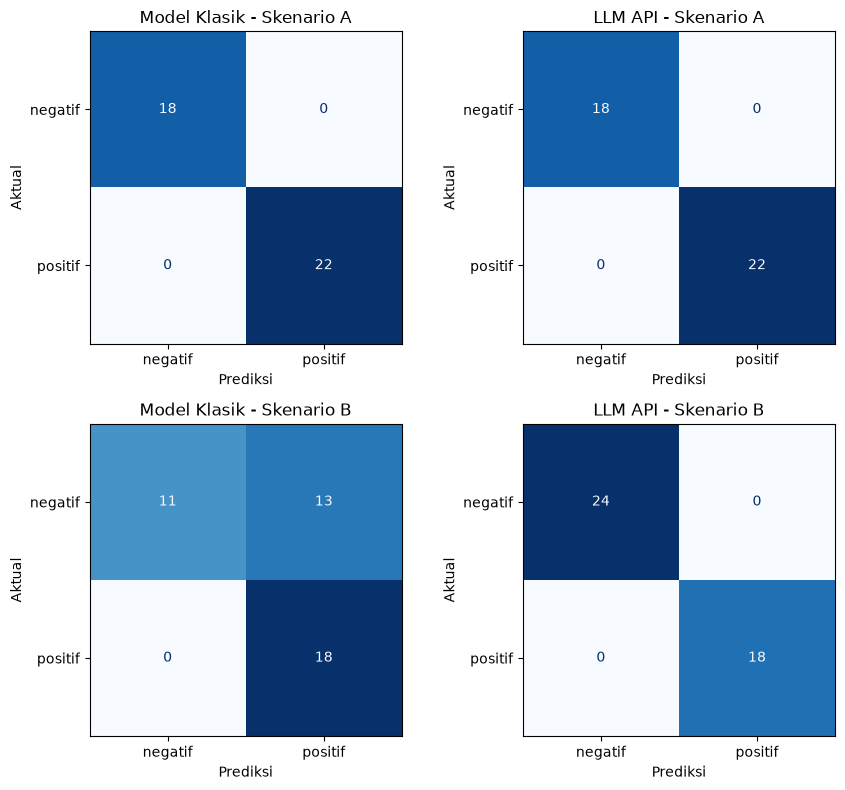

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
daftar = [
    ('Model Klasik - Skenario A', y_test, y_pred_classic),
    ('LLM API - Skenario A', y_test, y_pred_llm),
    ('Model Klasik - Skenario B', y_test_b, y_pred_classic_b),
    ('LLM API - Skenario B', y_test_b, y_pred_llm_b),
]
for ax, (judul, y_true, y_pred) in zip(axes.flat, daftar):
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=LABELS, ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(judul)
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Aktual')
plt.tight_layout()
plt.savefig(f'{DOC_DIR}/model_comparison_summary.png', dpi=120)
plt.show()

**Interpretasi:** di skenario A semua angka ada di diagonal, artinya tidak ada yang salah.
Di skenario B model klasik punya 13 ulasan negatif yang ditebak positif, dan tidak ada kebalikannya.
Jadi kesalahannya selalu sama: komplain dianggap pujian.

### 6.5 Uji Tambahan: Ulasan yang Lebih Sulit

Kalimat di dataset ini semuanya cukup jelas. Saya penasaran bagaimana kalau kalimatnya lebih susah, jadi saya buat 10 ulasan sendiri (bukan dari dataset)
yang isinya negasi, bahasa gaul, ulasan campuran, dan sindiran.
Hasil ini tidak saya masukkan ke tabel metrik utama, hanya untuk melihat kesalahan seperti apa yang dibuat masing-masing pendekatan.

In [23]:
uji_sulit = pd.DataFrame([
    ('U01', 'Barangnya lumayan, tidak buruk untuk harga segini.', 'positif', 'negasi'),
    ('U02', 'Gak nyesel beli di sini, seller amanah.', 'positif', 'gaul + negasi'),
    ('U03', 'Harga murah tapi kualitas tidak murahan.', 'positif', 'negasi'),
    ('U04', 'Awalnya ragu, ternyata kualitasnya jauh di atas ekspektasi.', 'positif', 'campuran'),
    ('U05', 'Recommended banget gan, barang ori.', 'positif', 'gaul'),
    ('U06', 'Bagus sih desainnya, tapi baru seminggu sudah patah.', 'negatif', 'campuran'),
    ('U07', 'Mantap, nunggu sebulan baru nyampe. Hebat sekali ekspedisinya.', 'negatif', 'sarkas'),
    ('U08', 'Kurirnya ramah, tapi isi paketnya salah dan seller tidak mau tanggung jawab.', 'negatif', 'campuran'),
    ('U09', 'Jelek parah, jangan beli di toko ini.', 'negatif', 'gaul'),
    ('U10', 'Warnanya pudar setelah sekali dicuci, nyesel beli.', 'negatif', 'kata baru'),
], columns=['review_id', 'review_text', 'aktual', 'kategori'])

uji_llm = jalankan_llm(uji_sulit, 'llm_predictions_uji_sulit.csv')
uji_sulit['pred_klasik'] = clf.predict(vectorizer.transform(uji_sulit['review_text']))
uji_sulit['prob_positif_klasik'] = clf.predict_proba(vectorizer.transform(uji_sulit['review_text']))[:, 1].round(2)
uji_sulit['pred_llm'] = uji_llm['jawaban_llm'].apply(normalisasi_label).values

print('Benar - model klasik:', (uji_sulit['pred_klasik'] == uji_sulit['aktual']).sum(), 'dari', len(uji_sulit))
print('Benar - LLM         :', (uji_sulit['pred_llm'] == uji_sulit['aktual']).sum(), 'dari', len(uji_sulit))
uji_sulit[['review_text', 'kategori', 'aktual', 'pred_klasik', 'prob_positif_klasik', 'pred_llm']]

Memakai hasil Gemini yang sudah tersimpan: ../documentation/llm_predictions_uji_sulit.csv
Benar - model klasik: 5 dari 10
Benar - LLM         : 10 dari 10


,review_text,kategori,aktual,pred_klasik,prob_positif_klasik,pred_llm
0,"Barangnya lumayan, tidak buruk untuk harga seg...",negasi,positif,positif,0.54,positif
1,"Gak nyesel beli di sini, seller amanah.",gaul + negasi,positif,positif,0.69,positif
2,Harga murah tapi kualitas tidak murahan.,negasi,positif,negatif,0.38,positif
3,"Awalnya ragu, ternyata kualitasnya jauh di ata...",campuran,positif,negatif,0.38,positif
4,"Recommended banget gan, barang ori.",gaul,positif,positif,0.74,positif
5,"Bagus sih desainnya, tapi baru seminggu sudah ...",campuran,negatif,negatif,0.36,negatif
6,"Mantap, nunggu sebulan baru nyampe. Hebat seka...",sarkas,negatif,negatif,0.39,negatif
7,"Kurirnya ramah, tapi isi paketnya salah dan se...",campuran,negatif,positif,0.60,negatif
8,"Jelek parah, jangan beli di toko ini.",gaul,negatif,positif,0.60,negatif
9,"Warnanya pudar setelah sekali dicuci, nyesel b...",kata baru,negatif,positif,0.57,negatif


**Interpretasi:** Gemini benar 10 dari 10, model klasik cuma 5. Probabilitas model klasik juga di kisaran 0,36 sampai 0,74, jadi sebenarnya dia ragu-ragu.

Beberapa salah tebak model klasik:
- "kualitas tidak murahan" → negatif, karena kata `tidak` dianggap negatif.
- "jauh di atas ekspektasi" → negatif, karena kata `jauh` biasanya muncul di "jauh dari ekspektasi".
- "Kurirnya ramah, tapi isi paketnya salah..." → positif, terpengaruh kata `ramah`.
- "Jelek parah, jangan beli di toko ini" → positif, karena "toko ini" biasanya muncul di "langganan di toko ini".

Dari sini kelihatan TF-IDF hanya menghitung kata tanpa paham maksud kalimatnya, sedangkan Gemini bisa membaca kalimat secara utuh.

### 6.6 Tabel Perbandingan Ringkasan

In [24]:
ringkasan = pd.DataFrame([
    hitung_metrik('Model Klasik - Skenario A', y_test, y_pred_classic),
    hitung_metrik('LLM API - Skenario A', y_test, y_pred_llm),
    hitung_metrik('Model Klasik - Skenario B', y_test_b, y_pred_classic_b),
    hitung_metrik('LLM API - Skenario B', y_test_b, y_pred_llm_b),
]).set_index('Pendekatan').round(4)

ringkasan.to_csv(f'{DOC_DIR}/evaluation_summary.csv')
ringkasan

,Accuracy,Precision (macro),Recall (macro),F1-Score (macro),Recall negatif
Pendekatan,,,,,
Model Klasik - Skenario A,1.0000,1.0000,1.0000,1.0000,1.0000
LLM API - Skenario A,1.0000,1.0000,1.0000,1.0000,1.0000
Model Klasik - Skenario B,0.6905,0.7903,0.7292,0.6816,0.4583
LLM API - Skenario B,1.0000,1.0000,1.0000,1.0000,1.0000


In [25]:
# Kecepatan dan biaya
# Harga gemini-3.5-flash-lite (paid tier, USD per 1 juta token): input 0.30, output 2.50
HARGA_INPUT = 0.30
HARGA_OUTPUT = 2.50

rata_input = llm_df['input_tokens'].mean()
rata_output = llm_df['output_tokens'].mean()
biaya_per_1000_ulasan = 1000 * (rata_input * HARGA_INPUT + rata_output * HARGA_OUTPUT) / 1_000_000

operasional = pd.DataFrame({
    'Model Klasik': [
        f'Perlu ({len(X_train)} ulasan, {waktu_training:.3f} detik)',
        f'{waktu_prediksi_classic * 1000:.3f} ms',
        'USD 0 (jalan di komputer sendiri)',
    ],
    'LLM API (Gemini)': [
        'Tidak perlu (zero-shot)',
        f"{llm_df['latency_detik'].mean() * 1000:.0f} ms (min {llm_df['latency_detik'].min():.1f} s, max {llm_df['latency_detik'].max():.1f} s)",
        f'sekitar USD {biaya_per_1000_ulasan:.3f} ({rata_input:.0f} token input + {rata_output:.0f} token output per ulasan)',
    ],
}, index=['Data berlabel & training', 'Waktu prediksi per ulasan', 'Biaya per 1.000 ulasan'])
operasional

,Model Klasik,LLM API (Gemini)
Data berlabel & training,"Perlu (160 ulasan, 0.009 detik)",Tidak perlu (zero-shot)
Waktu prediksi per ulasan,0.000 ms,"2455 ms (min 0.7 s, max 10.7 s)"
Biaya per 1.000 ulasan,USD 0 (jalan di komputer sendiri),sekitar USD 0.049 (147 token input + 2 token o...


**Interpretasi:** dari sisi hasil, di skenario A keduanya sama, tapi nilai model klasik di situ kurang bisa dipercaya karena kebocoran data tadi.
Di skenario B Gemini jelas lebih baik (F1 1,00 vs 0,68, recall negatif 1,00 vs 0,46).

Dari sisi kecepatan, model klasik jauh lebih cepat (kurang dari 1 ms per ulasan), sedangkan Gemini rata-rata sekitar 2,5 detik dan paling lama 10,7 detik.
Waktu dijalankan, beberapa kali juga kena error 429 (kuota per menit habis) jadi harus menunggu dulu.

Untuk biaya, model klasik gratis, sedangkan Gemini sekitar USD 0,05 per 1.000 ulasan. Biaya terbesarnya dari token input (prompt).

## 7. Analisis Trade-off dan Limitation

**Mana yang lebih unggul?**

Dari hasil eksperimen, Gemini lebih unggul, terutama untuk kalimat yang belum pernah dilihat.
Di skenario B F1-nya 1,00 vs 0,68, dan di uji tambahan 10/10 vs 5/10. Di skenario A memang sama-sama 1,00, tapi itu karena test set-nya bocor.

**Trade-off**
- Effort: model klasik perlu data berlabel dan harus dilatih, dan perlu dilatih ulang kalau gaya bahasa ulasan berubah.
  Gemini tidak perlu training, tapi tetap ada pekerjaannya: membuat prompt, merapikan jawaban, dan menangani error API.
- Data: 40 kalimat ternyata tidak cukup untuk model klasik. Gemini tidak butuh data latih, data berlabel hanya dipakai untuk mengecek hasilnya.
- Kecepatan: model klasik kurang dari 1 ms dan jalan di komputer sendiri. Gemini sekitar 2,5 detik per ulasan dan tergantung internet, server, dan kuota.
- Biaya: model klasik gratis. Gemini sekitar USD 0,05 per 1.000 ulasan, makin banyak ulasan makin mahal.
- Ketergantungan: model klasik sepenuhnya di tangan kita. Gemini tergantung Google, contohnya `gemini-2.5-flash` yang sudah tidak bisa dipakai lagi,
  dan isi ulasan harus dikirim ke luar.

**Keterbatasan**

Model klasik hanya menghafal kata, bukan memahami kalimat. Kata yang sebenarnya netral seperti `respon`, `ukuran`, atau `toko ini` bisa ikut menentukan hasil,
dan dia lemah kalau bertemu negasi, kalimat campuran, atau kata yang belum pernah dilihat.

Gemini lambat dan waktunya tidak stabil (0,7 sampai 10,7 detik), sempat kena error 429, biayanya naik sesuai jumlah ulasan,
dan modelnya bisa diganti atau dihentikan oleh Google. Di eksperimen ini Gemini belum pernah salah, tapi test set-nya kecil dan kalimatnya sederhana,
jadi belum tentu 100% juga di data asli (misalnya ulasan yang panjang atau netral).

Datasetnya sendiri hanya 40 kalimat unik, jadi hasil ini lebih cocok dianggap gambaran awal.

## 8. Rekomendasi Technical Approach

Saran saya, **pakai Gemini (LLM API) dulu untuk tahap awal**.

Alasannya:
1. Hasilnya lebih bagus di ulasan baru (F1 1,00 vs 0,68 di skenario B, 10/10 vs 5/10 di uji tambahan).
   Nilai sempurna model klasik di skenario A tidak bisa dijadikan patokan karena kebocoran data.
2. Komplain pelanggan tidak ada yang lolos (recall negatif 1,00 vs 0,46). Menurut saya ini yang paling penting untuk tim produk.
3. Tidak perlu data latih, sedangkan data yang ada sekarang (40 kalimat) belum cukup untuk melatih model klasik yang bagus.
4. Kekurangannya masih bisa diakali. Sentimen tidak harus muncul detik itu juga, jadi ulasan bisa diproses di belakang layar saat ulasan masuk,
   lalu hasilnya disimpan. Biaya USD 0,05 per 1.000 ulasan juga masih kecil.

Kalau jadi dipakai, yang perlu disiapkan: proses di belakang layar (bukan saat halaman dibuka), retry kalau kena error 429/503,
simpan hasilnya supaya ulasan yang sama tidak dikirim dua kali, dan sesekali cek akurasinya dengan ulasan yang dilabeli manual.

Ke depannya, kalau ulasan asli sudah banyak dan beragam, model klasik bisa dicoba lagi.
Kalau hasilnya sudah bagus, bisa pindah ke model klasik supaya lebih hemat dan tidak tergantung API.